In [1]:
from google.colab import files
uploaded = files.upload()


Saving retail_sales_dataset.csv to retail_sales_dataset.csv


In [2]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [8]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [9]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [3]:
print("Columns:", list(df.columns))
print("\nMissing values per column:")
print(df.isnull().sum())

Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Missing values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [4]:
print("Total Sales Amount:", df["Total Amount"].sum())
print("Average Transaction Amount:", round(df["Total Amount"].mean(), 2))
print("Total Quantity Sold:", df["Quantity"].sum())

category_sales = df.groupby("Product Category")["Total Amount"].sum()
print("\nTotal Sales by Product Category:")
print(category_sales)

Total Sales Amount: 456000
Average Transaction Amount: 456.0
Total Quantity Sold: 2514

Total Sales by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


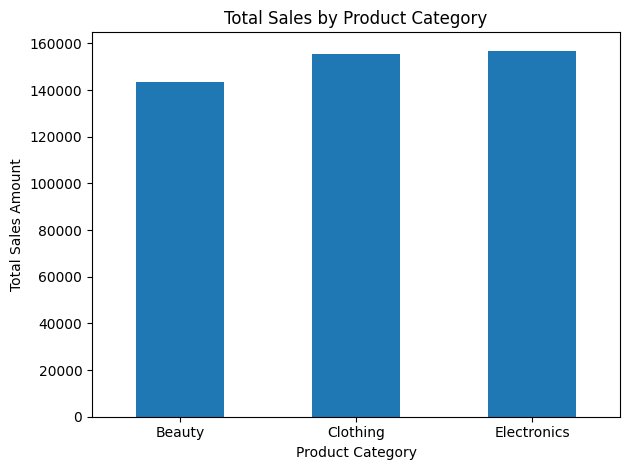

In [5]:
import matplotlib.pyplot as plt

category_sales.plot(kind="bar", title="Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
gender_summary = df.groupby("Gender")["Total Amount"].agg(["count", "mean", "sum"]).round(2)
print("Sales Breakdown by Gender:")
print(gender_summary)

Sales Breakdown by Gender:
        count    mean     sum
Gender                       
Female    510  456.55  232840
Male      490  455.43  223160


In [7]:
summary = pd.DataFrame({
    "Total Sales": [df["Total Amount"].sum()],
    "Average Order": [round(df["Total Amount"].mean(), 2)],
    "Total Orders": [len(df)],
    "Top Category": [category_sales.idxmax()]
})
summary

,Total Sales,Average Order,Total Orders,Top Category
0,456000,456.0,1000,Electronics


In [11]:
bins = [17, 25, 35, 50, 100]
labels = ["18-25", "26-35", "36-50", "51+"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

age_category = df.pivot_table(
    values="Total Amount",
    index="Age Group",
    columns="Product Category",
    aggfunc="sum",
    observed=False
)
print("Total Sales by Age Group and Product Category:")
print(age_category)

Total Sales by Age Group and Product Category:
Product Category  Beauty  Clothing  Electronics
Age Group                                      
18-25              31280     26510        26760
26-35              31240     39975        27265
36-50              49110     42975        47575
51+                31885     46120        55305


Monthly Sales:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


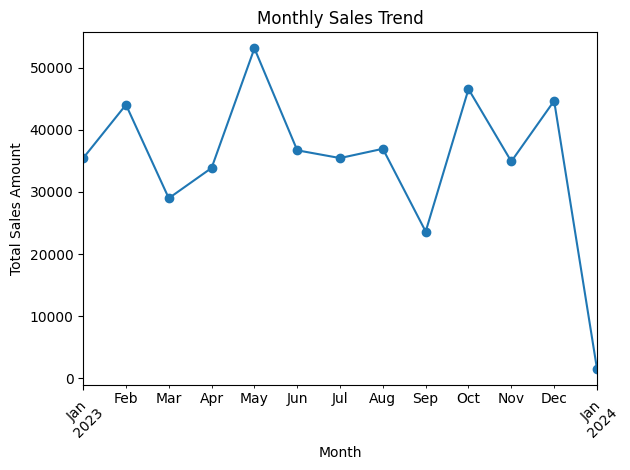

In [12]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()
print("Monthly Sales:")
print(monthly_sales)

monthly_sales.plot(kind="line", marker="o", title="Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()